# Visualization Comparison and Accuracy Evaluation of Different Methods
## 1. Comparison Methods
- ILK-VG, OF-VG, INR-EST, INR-VG, ConstGS, AffineGS

## 2. Test Data
- Three synthetic event streams corresponding to different simulated flow fields;

In [1]:
# The basic funcs
import json
import os
import numpy as np
import pandas as pd
import torch
from tqdm.notebook import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt

from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

from methods import inr_vg,inr_est,of_vg,of_est, ilk_vg, ilk_est, affineGS, constGS, compute_flow_quantities

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field,plot_event_time2d, create_colorbar
from utils.painter import plot_vortex_line_panel

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)              
torch.cuda.manual_seed(seed)         
torch.cuda.manual_seed_all(seed)    

# ====================== PyTorch ============================
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

CUDA acceleration: OK
Using device: cuda
Using device: cuda


# Test Data

In [2]:
flow0 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz")
flow1 = FlowManager(mode="data", data_path="./data/datasets/DNS_turbulence_00001_flow.npz")
flow2 = FlowManager(mode="data", data_path="./data/datasets/SQG_00001_flow.npz")
flow_names = ["JHTDB_isotropic", "DNS_turbulence", "SQG"]

In [3]:
def flow_metrics(div, omega_pred, omega_true):
    abs_div = np.abs(div)
    return {
        "mean_abs_div" : float(abs_div.mean()),
        "rmse_omega"   : float(np.sqrt(np.mean((omega_pred - omega_true) ** 2))),
    }

def build_wide_metrics_table(metrics_dict_list, flow_name_list=flow_names, method_order=None, round_digits=4):

    # 行顺序：六种方法
    if method_order is None:
        method_order = list(metrics_dict_list[0].keys())

    metrics_order = ["rmse", "aee", "mean|div|", "RMSE_ω"]

    # 构建二维数据
    data = {}
    for flow_name, metrics_dict in zip(flow_name_list, metrics_dict_list):
        for metric_name in metrics_order:
            col_key = (flow_name, metric_name)
            data[col_key] = [
                float(metrics_dict[method][metric_name]) if method in metrics_dict else float("nan")
                for method in method_order
            ]

    df = pd.DataFrame(data, index=method_order)
    df.index.name = "method"
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    df = df.round(round_digits)

    return df

# Methods

In [4]:
estimators = [ilk_vg, of_vg, inr_est, inr_vg, constGS, affineGS]
method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"]

def test(flow_index, coord_idx, H=256, W=256, error_map=True, plot_vor=True):

    flow_func = globals()[f"flow{flow_index}"].evaluate
    cfg_evts = config_events()
    cfg_evts.time_length = 4.01
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05

    evts, (u, v) = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func).load()
    v_h_gt = u.squeeze().cpu().numpy()
    v_w_gt = v.squeeze().cpu().numpy()
    div_gt, vor_gt = compute_flow_quantities(v_h_gt, v_w_gt)

    vor_list = [vor_gt]   # 第0通道 = GT
    names = ["ground truth"]

    # 新增：用于保存各方法指标
    metrics_dict = {}

    for i, m in enumerate(estimators):
        
        v_h, v_w, div, vor = m(evts, H=H, W=W)
        rmse, aee = PIVmetric(v_h, v_w, v_h_gt, v_w_gt, show=False)[:2]
        # print(f"结果精度：rmse: {rmse:.4f}、aee: {aee:.4f}")
        
        metric_vals = flow_metrics(div.detach().numpy(), vor.detach().numpy(), vor_gt.detach().numpy())
        # print(f"mean|div| : {metric_vals['mean_abs_div']:.4f}")
        # print(f"RMSE_ω    : {metric_vals['rmse_omega']:.4f}")

        # 新增：保存到字典
        metrics_dict[method_names[i]] = {
            "rmse": float(rmse),
            "aee": float(aee),
            "mean|div|": float(metric_vals["mean_abs_div"]),
            "RMSE_ω": float(metric_vals["rmse_omega"]),
        }

        names.append(method_names[i])
        vor_list.append(vor)
        
        if error_map:
            path = f"output/EXP2/on_single_flow/{flow_names[flow_index]}_{method_names[i]}.svg"

            plot_flow_field(v_h, v_w, v_h_gt, v_w_gt, output_file=path, magFlag=True, slFlag=False, colorbar_flag=False, step=1, quiver_step=32, 
                            v_min=0, v_max=0.5, scale=None, figsize=(2, 2), cbar_ticks=None, cbar_tick_size=12)

    vor_stack = torch.stack(vor_list, axis=0)   # [C, H, W]

    # 新增：返回指标字典
    return vor_stack, metrics_dict

Figure saved to output/EXP2/on_single_flow/JHTDB_isotropic_ILK_VG.svg


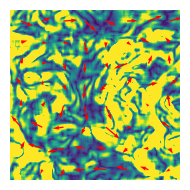

Figure saved to output/EXP2/on_single_flow/JHTDB_isotropic_OF_VG.svg


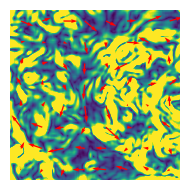

Figure saved to output/EXP2/on_single_flow/JHTDB_isotropic_INR_EST.svg


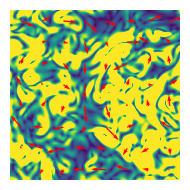

Figure saved to output/EXP2/on_single_flow/JHTDB_isotropic_INR_VG.svg


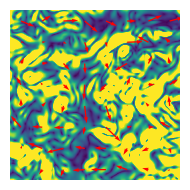

Figure saved to output/EXP2/on_single_flow/JHTDB_isotropic_ConstGS.svg


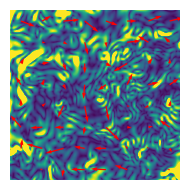

Figure saved to output/EXP2/on_single_flow/JHTDB_isotropic_AffineGS.svg


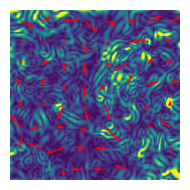

In [5]:
vor_stack0, metrics_dict0= test(flow_index = 0, coord_idx=128)
torch.cuda.empty_cache()

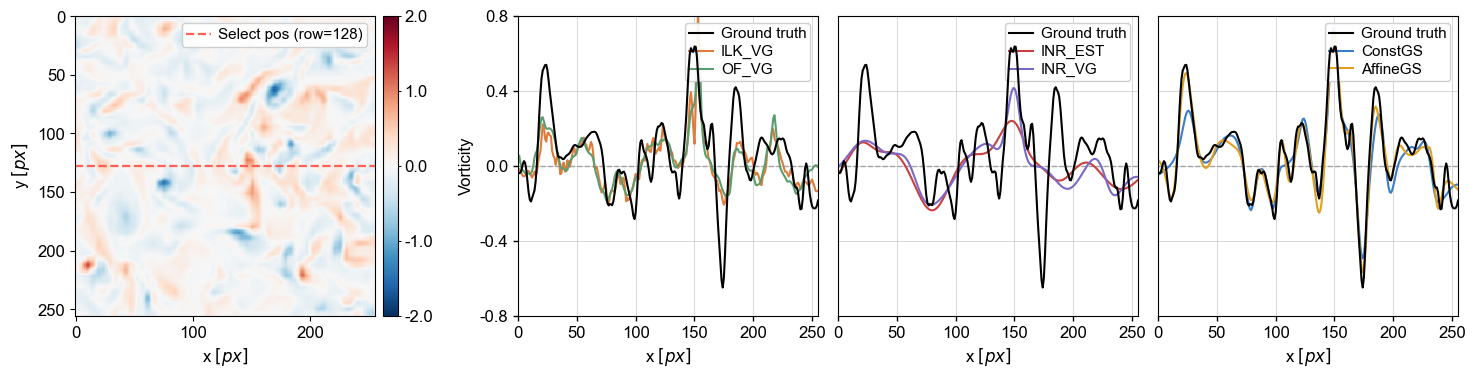

In [6]:
plot_vortex_line_panel(omega=vor_stack0, coord_idx=128, yticks=[-0.8, -0.4, 0, 0.4, 0.8], cbar_ticks=[-2, -1, 0, 1, 2], save_path="./output/fig10.pdf")

Figure saved to output/EXP2/on_single_flow/DNS_turbulence_ILK_VG.svg


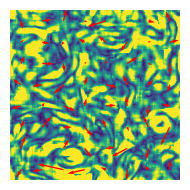

Figure saved to output/EXP2/on_single_flow/DNS_turbulence_OF_VG.svg


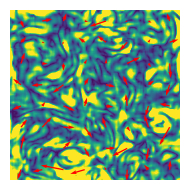

Figure saved to output/EXP2/on_single_flow/DNS_turbulence_INR_EST.svg


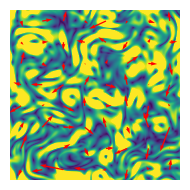

Figure saved to output/EXP2/on_single_flow/DNS_turbulence_INR_VG.svg


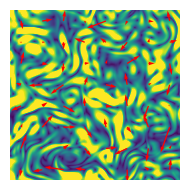

Figure saved to output/EXP2/on_single_flow/DNS_turbulence_ConstGS.svg


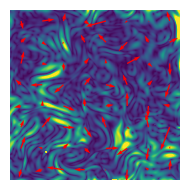

Figure saved to output/EXP2/on_single_flow/DNS_turbulence_AffineGS.svg


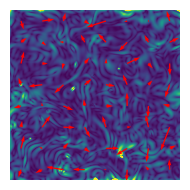

In [7]:
vor_stack1, metrics_dict1 = test(flow_index = 1, coord_idx=128)
torch.cuda.empty_cache()

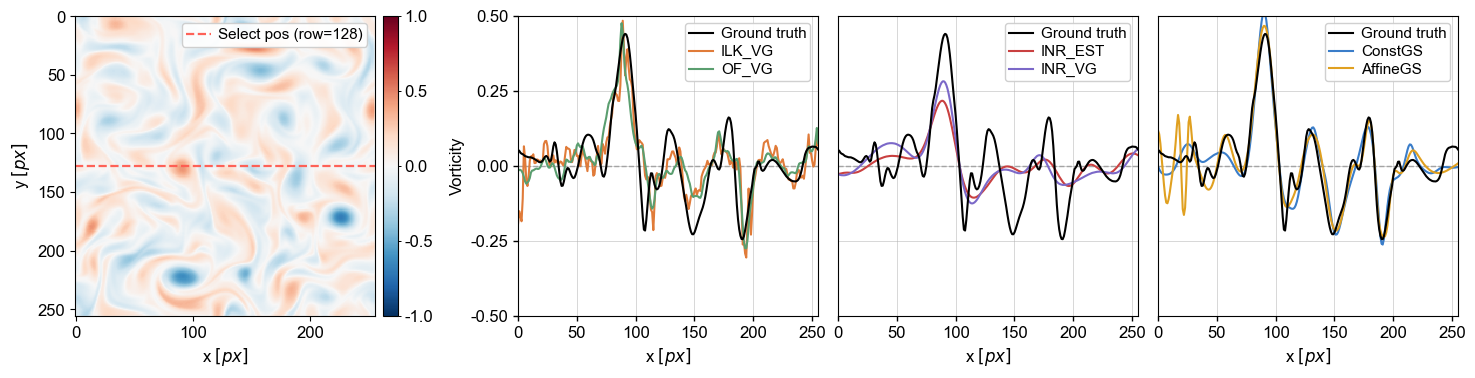

In [8]:
plot_vortex_line_panel(omega=vor_stack1, coord_idx=128, yticks=[-0.5, -0.25, 0, 0.25, 0.5], cbar_ticks=[-1, -0.5, 0, 0.5, 1], save_path=None)

Figure saved to output/EXP2/on_single_flow/SQG_ILK_VG.svg


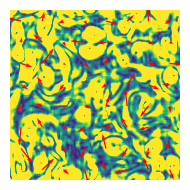

Figure saved to output/EXP2/on_single_flow/SQG_OF_VG.svg


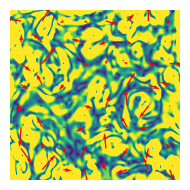

Figure saved to output/EXP2/on_single_flow/SQG_INR_EST.svg


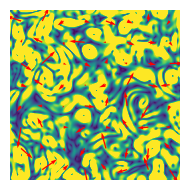

Figure saved to output/EXP2/on_single_flow/SQG_INR_VG.svg


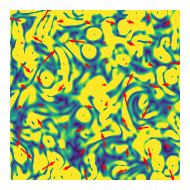

Figure saved to output/EXP2/on_single_flow/SQG_ConstGS.svg


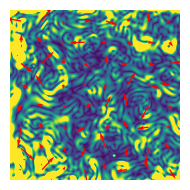

Figure saved to output/EXP2/on_single_flow/SQG_AffineGS.svg


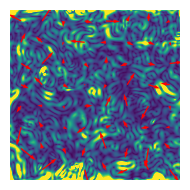

In [9]:
vor_stack2, metrics_dict2 = test(flow_index = 2, coord_idx=128)
torch.cuda.empty_cache()

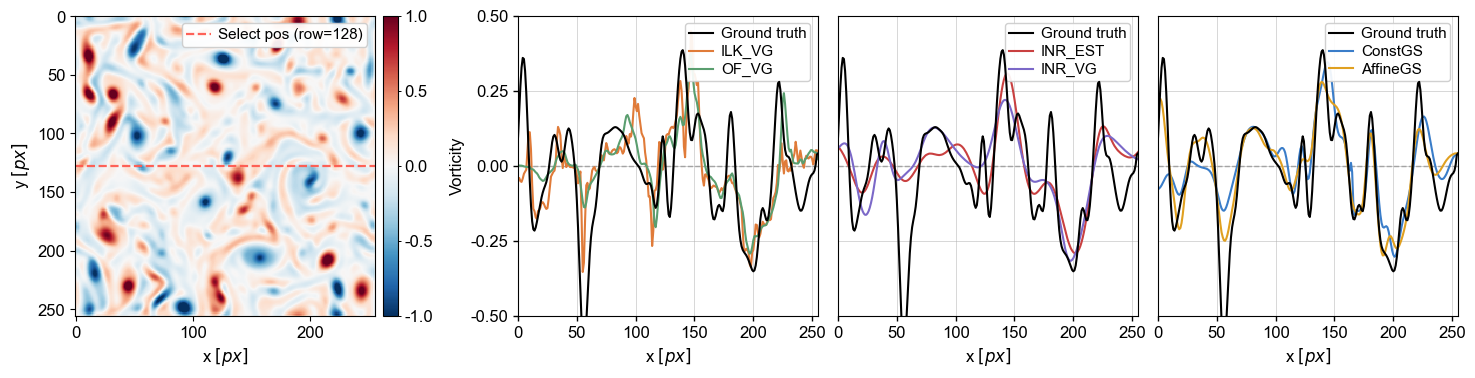

In [10]:
plot_vortex_line_panel(omega=vor_stack2, coord_idx=128, yticks=[-0.5, -0.25, 0, 0.25, 0.5], cbar_ticks=[-1, -0.5, 0, 0.5, 1], save_path=None)

In [11]:
build_wide_metrics_table(metrics_dict_list=[metrics_dict0, metrics_dict1, metrics_dict2],
    flow_name_list=flow_names, method_order=method_names, round_digits=4)

JHTDB_isotropic                           DNS_turbulence          \
                    rmse     aee mean|div|  RMSE_ω           rmse     aee   
method                                                                      
ILK_VG            0.6116  0.4538    0.0367  0.1437         0.4056  0.3407   
OF_VG             0.5472  0.4162    0.0317  0.1415         0.3574  0.2935   
INR_EST           0.6571  0.5010    0.0173  0.1535         0.4174  0.3543   
INR_VG            0.5599  0.4222    0.0172  0.1405         0.3672  0.3150   
ConstGS           0.2666  0.2061    0.0094  0.0891         0.1640  0.1305   
AffineGS          0.1615  0.1277    0.0045  0.0686         0.1156  0.0898   

                               SQG                            
         mean|div|  RMSE_ω    rmse     aee mean|div|  RMSE_ω  
method                                                        
ILK_VG      0.0334  0.0932  0.7343  0.5445    0.0442  0.2255  
OF_VG       0.0280  0.0827  0.6702  0.5209    0.0383  0.1675  
INR_EST     0.0138  0.0880  0.5848  0.4687    0.0287  0.1568  
INR_VG      0.0127  0.0830  0.6152  0.4963    0.0251  0.1670  
ConstGS     0.0057  0.0521  0.3864  0.2808    0.0181  0.1174  
AffineGS    0.0039  0.0522  0.2283  0.1719    0.0112  0.0922

Colorbar saved to ./output/EXP2/on_single_flow/JHTDB_isotropic.svg
Colorbar saved to ./output/EXP2/on_single_flow/DNS_turbulence.svg
Colorbar saved to ./output/EXP2/on_single_flow/SQG.svg


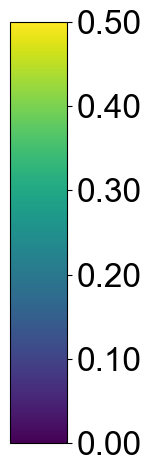

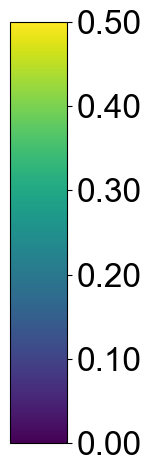

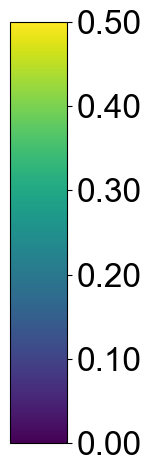

In [13]:
for flow_index in range(len(flow_names)):
    colorbar_path = f"./output/EXP2/on_single_flow/{flow_names[flow_index]}.svg"
    create_colorbar(0, 0.5, figsize=(1.6, 4.8), fontsize=24, orientation='vertical', 
                    output_file=colorbar_path, label=None)

## Datasets

In [ ]:
def save_results_to_json(results, save_path, indent=1):
    def convert_numpy_types(obj):
        if isinstance(obj, (np.integer, np.floating)): 
            return obj.item()
        elif isinstance(obj, np.ndarray): 
            return obj.tolist()
        return obj
    
    try:
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(results, f, ensure_ascii=False, indent=indent, default=convert_numpy_types)
        print(f"✅ Results saved to: {save_path}")
    except Exception as e:
        print(f"❌ Save failed: {e}")

In [ ]:
final_results = {}

data_index = 2
datasets_name = ["DNS_turbulence", "JHTDB_isotropic", "SQG"]

estimators = [ilk_vg, of_vg, inr_est, inr_vg, constGS, affineGS] 
method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"] 

valid_files_count=0
max_valid_files=1000

for file_idx in tqdm(range(1, 1201), desc="Processing files"):

    file_name = f"{datasets_name[data_index]}_{file_idx:05d}.npz"
    file_path = f"/media/newdisk/datasets_piv/piv_cai/train/{file_name}"

    if not os.path.exists(file_path):
        continue

    flow = FlowManager(mode="data", data_path=file_path)
    flow_func = flow.evaluate

    cfg_evts = config_events()
    cfg_evts.time_length = 4.01
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05

    evts, (u, v) = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func).load()
    v_h_gt = u.squeeze().cpu().numpy()
    v_w_gt = v.squeeze().cpu().numpy()

    file_key = f"{file_idx:05d}"
    final_results[file_key] = {}

    for method_idx, method in enumerate(estimators):

        name = method_names[method_idx]

        v_h, v_w, _, _ = method(evts, H=256, W=256)

        rmse, aee = PIVmetric(v_h, v_w, v_h_gt, v_w_gt, show=False)[:2]

        final_results[file_key][name] = {
            "rmse": round(float(rmse), 4),
            "aee": round(float(aee), 4)
        }

    valid_files_count += 1

    if valid_files_count % 200 == 0:
        save_results_to_json(final_results, f"./output/on_datasets/EXP2/{datasets_name[data_index]}({valid_files_count}).json")

    torch.cuda.empty_cache()

    if valid_files_count >= max_valid_files:
        break

In [ ]:
from utils.painter import plot_boxplot

datasets_name = ["JHTDB_isotropic", "DNS_turbulence", "SQG"]

def plot(data_index, datasets_name, use_Chinese = False, save=False):
    file_path = f"./output/EXP2/on_datasets/{datasets_name[data_index]}(1000).json"

    pdf_name = [["a", "b"], ["c", "d"], ["e", "f"]]
    
    if save is True:
        rmse_path = f"./output/EXP2/on_datasets/fig9-{pdf_name[data_index][0]}.pdf"
        aee_path = f"./output/EXP2/on_datasets/fig9-{pdf_name[data_index][1]}.pdf"
    else:
        rmse_path = None
        aee_path = None

    if use_Chinese is True:
        size = [18, 10]
    else:
        size = [12, 10]
        
    plot_boxplot(file_path, metric='rmse', save_path=rmse_path, 
        ylabel_en="RMSE $[px]$", ylabel_zh="RMSE $[px]$",
        xlabel_en='Methods', xlabel_zh='六种方法',
        title_en=None, title_zh=None,
        box_width=0.5, y_lim=(0, 0.8), 
        label_size=size[0], tick_size=size[1], 
        grid=True, use_chinese=use_Chinese, dataset_name=datasets_name[data_index]
    )
    
    plot_boxplot(file_path, metric='aee', save_path=aee_path, 
        ylabel_en="AEE $[px]$", ylabel_zh="AEE $[px]$",
        xlabel_en='Methods', xlabel_zh='六种方法',
        title_en=None, title_zh=None,
        box_width=0.5, y_lim=(0,0.8), 
        label_size=size[0], tick_size=size[1], 
        grid=True, use_chinese=use_Chinese, dataset_name=datasets_name[data_index]
    )

for data_index in range(3):
    print(f"dataset:{datasets_name[data_index]}")
    plot(data_index=data_index, datasets_name=datasets_name, use_Chinese = False, save=True)